Fit data to Naka Rushton

In [7]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from jaxopt import AndersonAcceleration
import pickle
import os
import optax
import pandas as pd
from scipy.optimize import curve_fit
from itertools import product
import openpyxl


# Model parameters
m = 2  # Number of mitral neurons (glomeruli)
x = jnp.ones(m)  # Input odour signal

## Modified Functions with Different n Values

Modify the Naka-Rushton function and circuit functions to accept different n values for each neuron type: n_r, n_g, n_b, n_y.


In [ ]:
# Naka-Rushton function
def nr(x, n=4):
    """Naka-Rushton activation function"""
    return x**n / (x**n + 1)

# Unpack parameters
def unpack_theta(theta, m):
    idx = 0
    w_osn_r = theta[idx:idx+m]; idx += m
    w_osn_b = theta[idx:idx+m]; idx += m
    w_osn_g = theta[idx:idx+m]; idx += m
    w_osn_y = theta[idx:idx+m]; idx += m
    w_b_r = theta[idx:idx+m]; idx += m
    w_b_g = theta[idx:idx+m]; idx += m
    w_b_y = theta[idx:idx+m]; idx += m
    w_r_y = theta[idx:idx+m]; idx += m
    w_r_g = theta[idx:idx+m]; idx += m
    alpha = theta[idx:idx+m]; idx += m
    W_g_r = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    W_g_y = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y

# Fixed-point function for green neurons with different n values
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r=4, n_b=4, n_g=4):
    """Fixed point equation for green neurons with different n values"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input, n=n_b)

    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input, n=n_r)

    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input, n=n_g)

    return g_new

# Solve fixed point via Anderson Acceleration with different n values
def solve_fixed_point(theta, x, m, n_r=4, n_b=4, n_g=4):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)
    g0 = jnp.zeros(m)

    # Create a function with the n values baked in that matches AndersonAcceleration signature
    def fixed_point_with_n(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha):
        return mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g)

    aa = AndersonAcceleration(fixed_point_with_n, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha)
    return solution.params

# Compute mitral output with different n values
def mitral_output(theta, x, m, n_r=4, n_b=4, n_g=4, n_y=4):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)

    g = solve_fixed_point(theta, x, m, n_r, n_b, n_g)
    b = nr(w_osn_b * alpha * x, n=n_b)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r, n=n_y)

    return r, g, b, y

# Mitral cells

In [9]:
df_mitral_unperturbed = pd.read_excel(
    'elisa_nr_data/Galliano et al 2021 - fig 4 ephys.xlsx',
    sheet_name='repetitive firing',
    index_col=0,
    skiprows=3,
    usecols='A,G:AB',
    nrows=45
)
df_mitral_unperturbed

,Cell 1,Cell 3,Cell 4,Cell 5,Cell 6,Cell 6.1,Cell 5.1,Cell 3.1,Cell 1.1,Cell 9,...,Cell 4.1,Cell 3.2,Cell 3.3,Cell A,Cell B,Cell C,Cell D,Cell E,Cell D.1,Cell G
bin,,,,,,,,,,,,,,,,,,,,,
0,0,0.0,0.0,0.0,0,0,0,0,0.00,0,...,0.0,0,0,0.00,0.00,0.00,0.0,0.00,0.00,0
10,0,0.5,0.0,0.0,0,0,0,0,0.00,0,...,0.0,0,0,0.50,0.00,0.75,0.0,0.50,0.00,0
20,0,2.0,0.0,0.0,0,0,0,0,0.00,0,...,1.0,0,0,2.50,0.00,3.75,0.0,2.00,0.00,0
30,0,5.0,0.0,0.0,0,0,0,0,0.00,0,...,3.0,0,0,4.25,0.00,6.50,0.0,5.00,0.00,0
40,0,7.0,0.0,0.0,0,0,0,0,0.00,0,...,NaN,0,0,5.50,0.00,12.00,1.5,7.25,0.00,0
50,0,11.0,0.0,0.0,0,0,0,0,0.00,0,...,8.0,0,0,7.50,0.00,14.50,3.0,9.50,0.00,0
60,3,16.5,0.0,0.5,0,0,0,0,0.00,0,...,13.0,0,0,8.50,0.75,19.50,4.5,11.75,0.00,0
70,4,17.0,0.0,2.5,0,0,0,0,0.00,0,...,16.0,0,0,10.75,1.50,25.00,6.0,14.25,0.00,0
80,10,16.0,0.0,3.5,0,0,0,0,0.00,0,...,NaN,0,0,13.75,3.50,30.50,7.5,16.50,0.00,0


In [10]:
df_mitral_occluded = pd.read_excel(
    'elisa_nr_data/Galliano et al 2021 - fig 4 ephys.xlsx',
    sheet_name='repetitive firing',
    index_col=0,
    skiprows=3,
    usecols='A,AG:BE',
    nrows=45
)
df_mitral_occluded

,Cell 3.4,Cell 2,Cell 1.2,Cell 5.2,Cell 4.2,Cell 3.5,Cell 1.3,Cell 7.1,Cell 6.2,Cell 5.3,...,Cell4,Cell 5.4,Cell 2.2,Cell 4.4,Cell B_av,Cell_D,Cell 9.1,Cell 11,Cell 3.8,Cell 6.3
bin,,,,,,,,,,,,,,,,,,,,,
0,0,0.000000,0,0,0,0.0,0.0,0,0.000000,0,...,0.0,0,0.0,0.0,0.000000,0.0,0.0,0.0,NaN,0
10,0,0.000000,0,0,0,0.0,0.0,0,0.000000,0,...,0.0,0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0
20,0,0.000000,0,0,0,0.0,0.0,0,0.000000,0,...,0.0,0,5.0,0.0,0.000000,0.0,1.5,0.0,0.0,0
30,0,0.000000,0,0,2,0.0,0.0,0,0.000000,0,...,0.0,0,7.0,0.0,0.000000,0.0,2.5,0.0,0.0,0
40,0,0.000000,0,0,4,0.0,0.0,0,0.000000,0,...,0.0,0,8.0,3.0,0.000000,0.0,4.0,0.0,0.0,0
50,0,0.000000,0,0,7,0.0,0.0,0,0.000000,0,...,0.0,0,9.5,6.0,0.000000,0.0,6.0,0.0,0.0,0
60,0,0.000000,0,0,10,0.0,2.5,0,0.000000,0,...,0.0,0,12.0,7.0,0.000000,0.0,8.0,0.0,0.0,0
70,0,0.000000,0,0,14,1.0,4.5,0,0.000000,0,...,0.0,0,13.5,16.0,0.000000,0.0,9.0,0.0,0.0,0
80,0,0.000000,0,0,18,0.0,4.0,0,0.666667,0,...,0.0,0,16.0,17.0,0.000000,0.0,10.5,0.0,0.0,0


<Axes: xlabel='bin '>

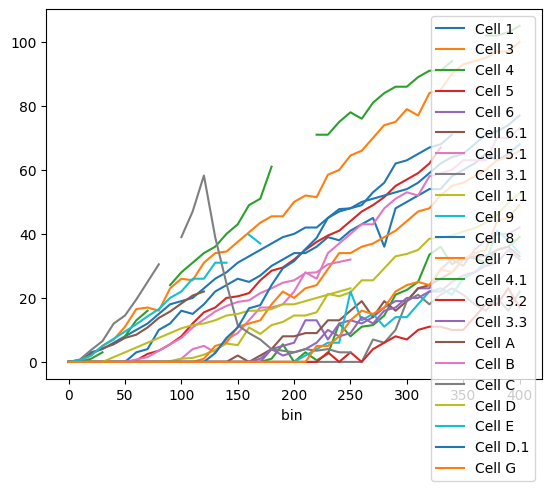

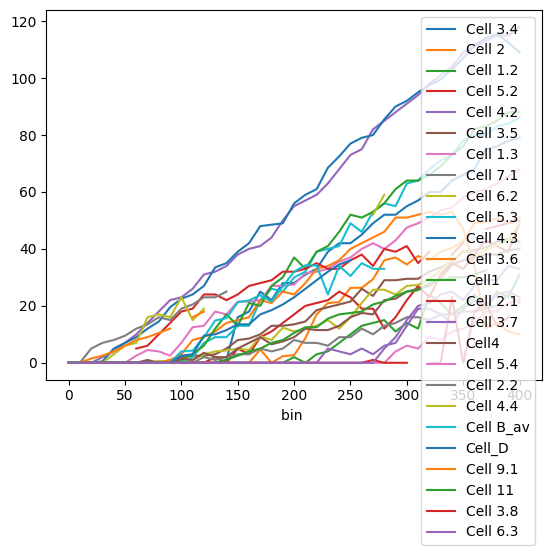

In [11]:
df_mitral_unperturbed.plot()
df_mitral_occluded.plot()

n =  2.353608775142701
b =  315.8292755679549


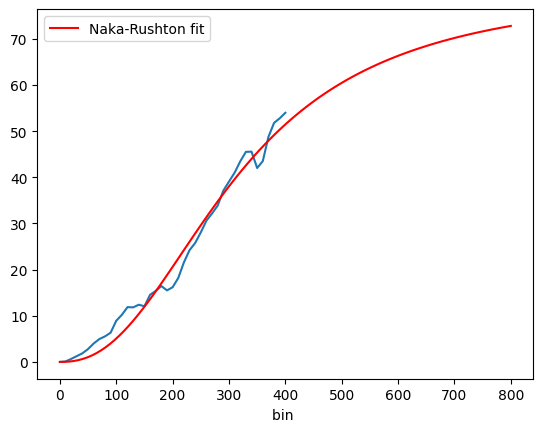

In [ ]:
df_plot = df_mitral_unperturbed
x = df_plot.index
y = df_plot.mean(axis=1)

def nr_full(x, n, b, y_max):
    x = x / b
    return nr(x, n) * y_max

fit_params, _ = curve_fit(nr_full, x, y, p0=[3, 200, 100])
print("n = ", fit_params[0])
print("b = ", fit_params[1])
df_plot.mean(axis=1).plot()

# plot fit
x_fit = np.linspace(x.min(), 2*x.max(), 100)
y_fit = nr_full(x_fit, *fit_params)
plt.plot(x_fit, y_fit, 'r-', label='Naka-Rushton fit')
plt.legend()
plt.show()


# Red cells (ETCs)

In [15]:
df_red_unperturbed = pd.read_excel(
    'elisa_nr_data/Galliano et al 2021 - fig 5 ephys.xlsx',
    sheet_name='ETC repetitive firing',
    index_col=0,
    skiprows=4,
    usecols='J,N:AQ',
    nrows=35
).dropna(how='all').astype(float)
df_red_unperturbed

,20160406A,20160406B,20160406C,20160406E,20160406F,20160406H,20160229A,20160229B,20160229D,20160224A,...,20160411A,20160411E,20160309C,20160309I,20160307B,20160215A,20160215D,20160215F,20160216F,20160307D
Bin Centre,,,,,,,,,,,,,,,,,,,,,
5.0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,NaN,0.0,0.0,...,0.0000,6.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0
15.0,0.0,2.0,3.0,3.0,0.0,3.5,0.0,0.0,NaN,NaN,...,1.3333,18.0,0.0,1.5,0.0000,0.0,3.0,12.0,0.0,0.0
25.0,0.0,8.0,5.0,10.0,0.0,0.0,0.0,NaN,NaN,NaN,...,0.0000,26.0,0.0,6.0,0.0000,0.0,8.0,4.0,0.0,0.5
35.0,2.0,13.0,6.0,16.5,0.5,0.0,0.0,NaN,15.0,0.0,...,1.3333,27.0,0.0,10.0,0.0000,2.0,NaN,4.0,0.0,2.5
45.0,11.0,NaN,12.5,21.5,2.0,3.5,0.0,NaN,20.0,0.0,...,9.6667,31.5,0.0,14.5,0.0000,9.5,33.0,21.0,0.0,4.5
55.0,13.0,23.0,15.5,25.5,6.0,4.5,0.0,NaN,25.0,7.0,...,16.0000,34.0,0.5,17.0,0.8333,19.0,26.0,17.0,0.0,8.0
65.0,15.0,NaN,20.5,28.5,11.5,6.0,0.0,NaN,32.0,7.0,...,16.6667,NaN,3.5,22.5,2.2000,22.0,37.0,20.0,0.0,12.0
75.0,22.0,33.0,20.0,33.5,16.5,10.0,0.0,NaN,34.0,NaN,...,30.0000,45.0,5.5,25.5,5.2500,25.5,NaN,20.0,0.0,15.5
85.0,NaN,36.0,17.5,35.5,19.5,14.0,0.0,19.0,37.0,NaN,...,27.5000,51.5,12.5,29.0,8.1250,28.5,47.0,47.0,0.0,21.0


In [16]:
df_red_occluded = pd.read_excel(
    'elisa_nr_data/Galliano et al 2021 - fig 5 ephys.xlsx',
    sheet_name='ETC repetitive firing',
    index_col=0,
    skiprows=41,
    usecols='J,N:AQ',
    nrows=73
).dropna(how='all').astype(float)
df_red_unperturbed

,20160406A,20160406B,20160406C,20160406E,20160406F,20160406H,20160229A,20160229B,20160229D,20160224A,...,20160411A,20160411E,20160309C,20160309I,20160307B,20160215A,20160215D,20160215F,20160216F,20160307D
Bin Centre,,,,,,,,,,,,,,,,,,,,,
5.0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,NaN,0.0,0.0,...,0.0000,6.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0
15.0,0.0,2.0,3.0,3.0,0.0,3.5,0.0,0.0,NaN,NaN,...,1.3333,18.0,0.0,1.5,0.0000,0.0,3.0,12.0,0.0,0.0
25.0,0.0,8.0,5.0,10.0,0.0,0.0,0.0,NaN,NaN,NaN,...,0.0000,26.0,0.0,6.0,0.0000,0.0,8.0,4.0,0.0,0.5
35.0,2.0,13.0,6.0,16.5,0.5,0.0,0.0,NaN,15.0,0.0,...,1.3333,27.0,0.0,10.0,0.0000,2.0,NaN,4.0,0.0,2.5
45.0,11.0,NaN,12.5,21.5,2.0,3.5,0.0,NaN,20.0,0.0,...,9.6667,31.5,0.0,14.5,0.0000,9.5,33.0,21.0,0.0,4.5
55.0,13.0,23.0,15.5,25.5,6.0,4.5,0.0,NaN,25.0,7.0,...,16.0000,34.0,0.5,17.0,0.8333,19.0,26.0,17.0,0.0,8.0
65.0,15.0,NaN,20.5,28.5,11.5,6.0,0.0,NaN,32.0,7.0,...,16.6667,NaN,3.5,22.5,2.2000,22.0,37.0,20.0,0.0,12.0
75.0,22.0,33.0,20.0,33.5,16.5,10.0,0.0,NaN,34.0,NaN,...,30.0000,45.0,5.5,25.5,5.2500,25.5,NaN,20.0,0.0,15.5
85.0,NaN,36.0,17.5,35.5,19.5,14.0,0.0,19.0,37.0,NaN,...,27.5000,51.5,12.5,29.0,8.1250,28.5,47.0,47.0,0.0,21.0


<Axes: xlabel='Bin Centre'>

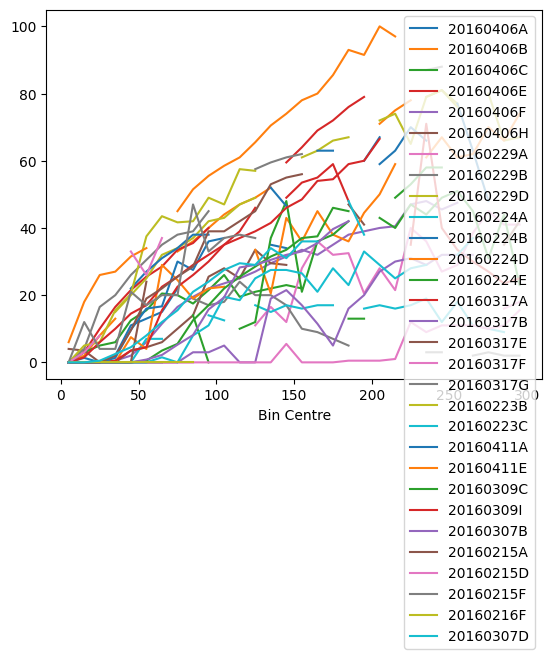

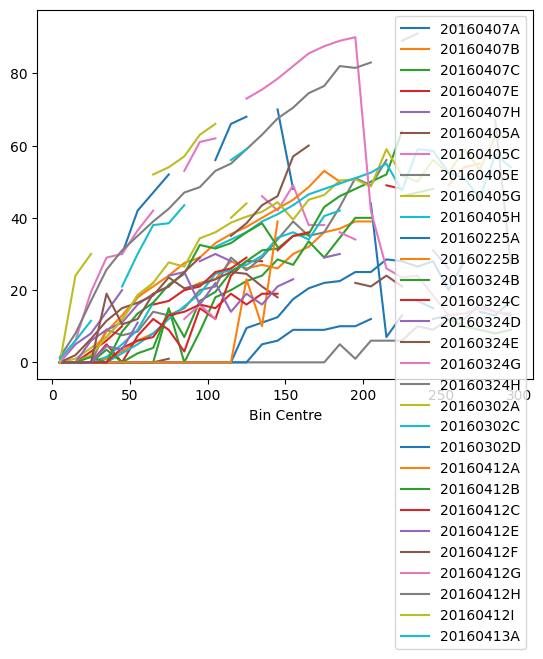

In [17]:
df_red_unperturbed.plot()
df_red_occluded.plot()

n =  1.979814483521794
b =  89.03697739941907


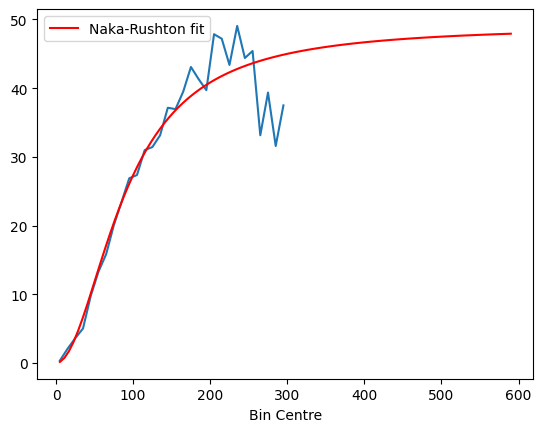

In [18]:
df_plot = df_red_unperturbed
x = df_plot.index
y = df_plot.mean(axis=1)

def nr_full(x, n, b):
    x = x / b
    return nr(x, n) * y.max()

fit_params, _ = curve_fit(nr_full, x, y, p0=[3, 200])
print("n = ", fit_params[0])
print("b = ", fit_params[1])
df_plot.mean(axis=1).plot()

# plot fit
x_fit = np.linspace(x.min(), 2*x.max(), 100)
y_fit = nr_full(x_fit, *fit_params)
plt.plot(x_fit, y_fit, 'r-', label='Naka-Rushton fit')
plt.legend()
plt.show()

# Green cells

In [19]:
df_green_unperturbed = pd.read_excel(
    'elisa_nr_data/Galliano et al 2021 - DA cells ephys repetitive firing.xlsx',
    sheet_name='DA cells (Fig 7 and 8)',
    index_col=0,
    skiprows=4,
    usecols='A,C:L',
    nrows=51
).dropna(how='all').astype(float)
df_green_unperturbed

,B,D,B.1,B.2,B.3,C,B.4,B.5,C.1,D.1
pA,,,,,,,,,,
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,11.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,1.0,0.0,21.0,0.0,0.0,1.0
8,0.0,0.0,2.0,0.0,2.0,0.0,29.0,0.0,0.0,4.0
10,0.0,0.0,2.0,0.0,3.0,0.0,34.0,0.0,0.0,6.0
12,0.0,1.0,4.0,0.0,4.0,0.0,38.0,0.0,0.0,8.0
14,1.0,1.0,4.0,0.0,5.0,0.0,28.0,0.0,0.0,11.0
16,2.0,1.0,5.0,0.0,5.0,0.0,24.0,0.0,0.0,11.0


In [20]:
df_green_occluded = pd.read_excel(
    'elisa_nr_data/Galliano et al 2021 - DA cells ephys repetitive firing.xlsx',
    sheet_name='DA cells (Fig 7 and 8)',
    index_col=0,
    skiprows=4,
    usecols='A,Y:AH',
    nrows=51
).dropna(how='all').astype(float)
df_green_occluded

,A.6,D.2,D.3,A.7,D.4,E,B.7,B.8,B.9,C.4
pA,,,,,,,,,,
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
10,0.0,1.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0
12,0.0,1.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0
14,0.0,1.0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0.0
16,0.0,1.0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,2.0


<Axes: xlabel='pA'>

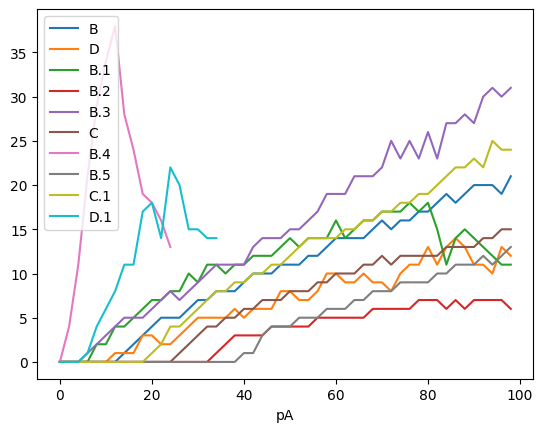

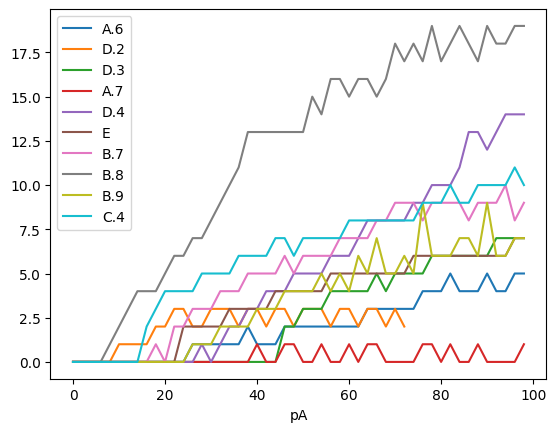

In [21]:
df_green_unperturbed.plot()
df_green_occluded.plot()

[ 2.06261351 56.02057133]


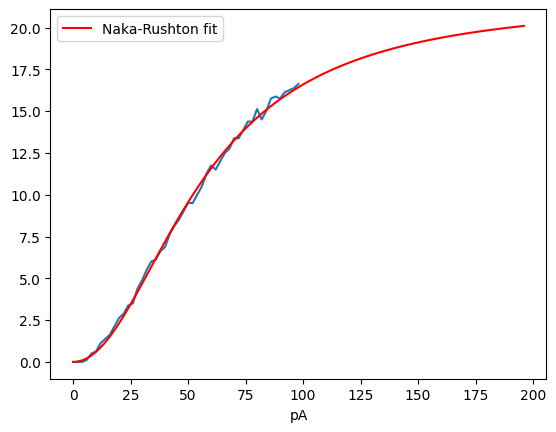

In [ ]:
df_plot = df_green_unperturbed.drop(columns=['B.4', 'D.1'])
x = df_plot.index
y = df_plot.mean(axis=1)

def nr_full(x, n, b):
    x = x / b
    return nr(x, n) * y.max() * 1.3

fit_params, _ = curve_fit(nr_full, x, y, p0=[3, 200])
print(fit_params)
df_plot.mean(axis=1).plot()

# plot fit
x_fit = np.linspace(x.min(), 2*x.max(), 100)
y_fit = nr_full(x_fit, *fit_params)
plt.plot(x_fit, y_fit, 'r-', label='Naka-Rushton fit')
plt.legend()
plt.show()

# Blue cells

In [23]:
df_blue_unperturbed = pd.read_excel(
    'elisa_nr_data/Galliano et al 2021 - DA cells ephys repetitive firing.xlsx',
    sheet_name='DA cells (Fig 7 and 8)',
    index_col=0,
    skiprows=4,
    usecols='A,N:V',
    nrows=51
).dropna(how='all').astype(float)
df_blue_unperturbed

,A,B.6,C.2,A.1,A.2,C.3,A.3,A.4,A.5
pA,,,,,,,,,
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0
6,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,3.0
8,0.0,2.0,0.0,0.0,0.0,2.0,4.0,0.0,5.0
10,0.0,4.0,0.0,1.0,0.0,2.0,5.0,0.0,8.0
12,0.0,3.0,2.0,1.0,0.0,3.0,5.0,0.0,10.0
14,0.0,4.0,2.0,3.0,0.0,4.0,9.0,0.0,11.0
16,1.0,4.0,2.0,3.0,0.0,4.0,10.0,0.0,14.0


In [24]:
df_blue_occluded = pd.read_excel(
    'elisa_nr_data/Galliano et al 2021 - DA cells ephys repetitive firing.xlsx',
    sheet_name='DA cells (Fig 7 and 8)',
    index_col=0,
    skiprows=4,
    usecols='A,AJ:AP',
    nrows=51
).dropna(how='all').astype(float)
df_blue_occluded

,F,C.5,A.8,C.6,B.10,A.9,E.1
pA,,,,,,,
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,3.0,0.0,0.0,0.0,0.0,0.0,0.0
10,6.0,0.0,0.0,0.0,0.0,0.0,0.0
12,6.0,0.0,0.0,0.0,0.0,0.0,0.0
14,7.0,0.0,0.0,0.0,0.0,0.0,1.0
16,8.0,0.0,0.0,0.0,0.0,1.0,1.0


<Axes: xlabel='pA'>

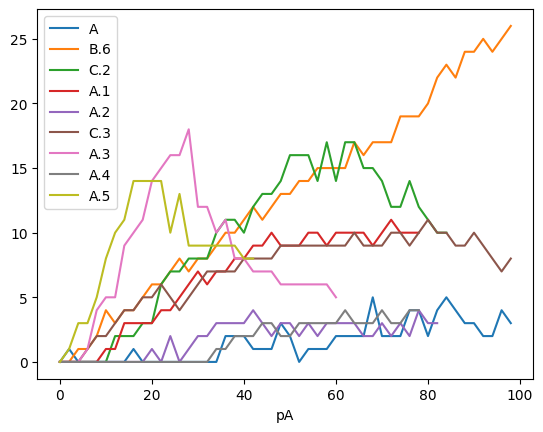

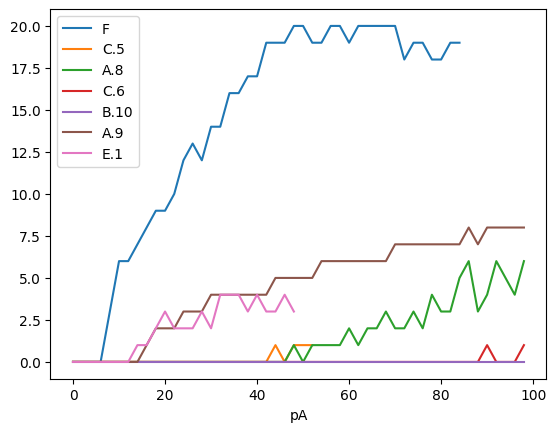

In [ ]:
df_blue_unperturbed.plot()
df_blue_occluded.plot()

[ 1.10663112 50.81828295]


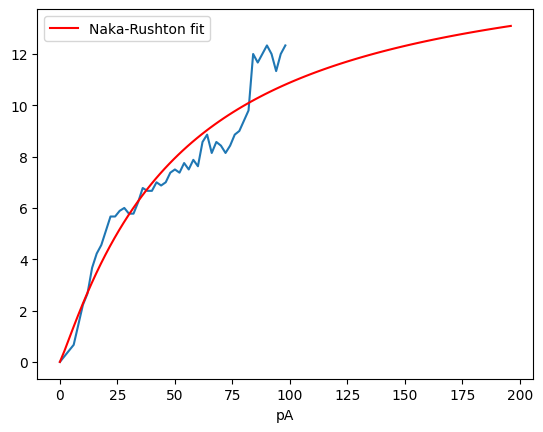

In [27]:
df_plot = df_blue_unperturbed
x = df_plot.index
y = df_plot.mean(axis=1)

def nr_full(x, n, b):
    x = x / b
    return nr(x, n) * y.max() * 1.3

fit_params, _ = curve_fit(nr_full, x, y, p0=[3, 200])
print(fit_params)
df_plot.mean(axis=1).plot()

# plot fit
x_fit = np.linspace(x.min(), 2*x.max(), 100)
y_fit = nr_full(x_fit, *fit_params)
plt.plot(x_fit, y_fit, 'r-', label='Naka-Rushton fit')
plt.legend()
plt.show()